**Modelos predictivo de Oulad con research data:**

Regresión: Lineal, Logistica
Clasificación: Bayes, Gausiano, Decision Tree
NSML: Clustering/Dimensionalidad

*   2025 UASD
*   Dr. Silverio Del Orbe A.



In [ ]:
%matplotlib inline
import statistics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn import preprocessing
from itertools import compress

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier, \
    BaggingClassifier, ExtraTreesClassifier, GradientBoostingClassifier,GradientBoostingRegressor

from xgboost.sklearn import XGBClassifier
from sklearn.neural_network import MLPClassifier # Deep Learning ANN
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC, NuSVC, LinearSVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# Decision tree
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score

from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, r2_score, mean_squared_error, \
    confusion_matrix, roc_curve, RocCurveDisplay
import shap
from shap import Explanation
import json

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imbpipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from numpy import ndarray
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from google.colab import drive
drive.mount('/content/gdrive')
# Reference: Logistic Regression, SVM, Naive Bayes, DecissionTree, Multi-Layer Perceptron
#final_resuklt (rq2)
#final_resuklt has procatina [0,1] (rq1)
#scale continues/intervals  [0 ...100] (rq3)
classifiers_default = {
    'LogisticRegression' : LogisticRegression(n_jobs=-1),

    'Support Verctor Machine' : SVC(), # default rbf, degree=3 with poly, scale, C=1.0

    'KNeighbors' : KNeighborsClassifier(),

    'GaussianNB' : GaussianNB(),

    'LinearDiscriminantAnalysis' : LinearDiscriminantAnalysis(),

    'DecisionTree' : DecisionTreeClassifier(),

    'AdaBoost' : AdaBoostClassifier(),
    'Bagging' : BaggingClassifier(n_jobs=-1),
    'ExtraTrees' : ExtraTreesClassifier(n_jobs=-1),
    'RandomForest' : RandomForestClassifier(n_jobs=-1),
    'XGBoost' : XGBClassifier(n_jobs=-1, use_label_encoder=False), # just for removing warning
    # see https://stackoverflow.com/questions/45251126/deprecation-warning-on-xgboost-sklearn
    # 512, 256, 128, 64 cuadro capas para el ANN
    'MLP' : MLPClassifier(max_iter=1024,random_state=1, hidden_layer_sizes=(100, 50), learning_rate='adaptive'),

}
Regressors_default = {
    'LinearRegression' : LinearRegression(fit_intercept=True,copy_X=True,n_jobs=None,positive=False),
    'RandomForestRegressor' : RandomForestRegressor(n_estimators=100, max_depth=None, max_features='sqrt'),
    'GradientBoostingRegressor' : GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=6),
    'XGBRegressor' : XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6),
    'LGBMRegressor' : LGBMRegressor(n_estimators=100, learning_rate=0.1, max_depth=6),
    'Ridge' : Ridge(alpha=1.0,fit_intercept=True,copy_X=True,max_iter=None,tol=1e-4,solver='auto',positive=False,random_state=None),
    'Lasso' : Lasso( alpha=1.0,fit_intercept=True,precompute=False,copy_X=True,max_iter=1000,tol=1e-4,warm_start=False,positive=False,random_state=None,selection='cyclic'),
    'ElasticNet' : ElasticNet(alpha=1.0, l1_ratio=0.5)
}


def get_master_vle():
    # select 26 rows from SQL table to insert in dataframe.
    base_path = "gdrive/My Drive/Colab Notebooks/datasets/"
    df_path_vle1 = f"{base_path}Full_vle_train.csv"
    df1_vle = pd.read_csv(df_path_vle1, encoding='latin1')
    return df1_vle
def get_master_assess():
    # select 26 rows from SQL table to insert in dataframe.
    base_path = "gdrive/My Drive/Colab Notebooks/datasets/"
    df_path_assess2 = f"{base_path}Full_assess_train.csv"
    df2_assess = pd.read_csv(df_path_assess2, encoding='latin1')
    return df2_assess
def outlier_boxplt(df, name, base_wd):
    plt.clf()
    fig_outliers = sns.boxplot(x='variable', y='value', data=pd.melt(df))
    fig_outliers.set_xticklabels(fig_outliers.get_xticklabels(), rotation=90)
    plt.tight_layout()
    fig_outliers.figure.savefig(base_wd + '/outputs/plots/cleaning/' + name + '_outlier_boxplots.png')
def feature_eng_clean(df, base_wd, name, rq):

    # transform code_presentation into year and semester columns
    df['year'] = df['code_presentation'].str.strip().str[0:4]
    df['semester'] = df['code_presentation'].str.strip().str[-1]
    df2 = df.copy(deep=True)

    # one hot encoding for OOS regression (RQ2)
    # ohe_cols = ['final_result', 'age_band', 'imd_band', 'disability', 'gender', 'region', 'highest_education',
    #             'code_module', 'assessment_type']
    # ohe_df = pd.get_dummies(df, columns=ohe_cols,  drop_first=True)  # drop_first to avoid singularity
    # df2 = pd.concat([df, ohe_df], axis=1)
    # df2 = df2.T.drop_duplicates().T

    ### df2['Reg02'] = df2['region']
    df2['FResult02'] = df2['final_result']
    # FResult02_Fail [0,1],  FResult02_Wi,,,  FResult02_Pass
    df2 = pd.get_dummies(df2, columns=['FResult02'], drop_first=True)

    # label encoding categorical variables
    if rq == 3:
        le_cols = ['final_result', 'age_band', 'imd_band', 'disability', 'gender', 'region', 'highest_education',
                   'code_module', 'assessment_type', 'semester']
    if rq in {1,2}:
        le_cols = ['final_result', 'age_band', 'imd_band', 'disability', 'gender', 'region', 'highest_education',
                   'code_module', 'semester']

    label_encoder = preprocessing.LabelEncoder()

    for col in le_cols:
        df2[col] = label_encoder.fit_transform(df2[col])

    # create overall total clicks column
    df2['overall_total_clicks'] = df2['total_n_days'] * df2['avg_total_sum_clicks']

    # check for relationship between final exam score and final_result (i.e., course outcome)
    if rq == 3:
        plt.clf()
        sns.set_style("whitegrid")
        scores_plot = sns.boxplot(x='final_result', y='score', data=df, palette="Set3")
        plt.tight_layout()
        scores_plot.figure.savefig(base_wd + '/outputs/plots/cleaning/' + name + '_scores_plot.png')

    return df2
def basic_clean(df, base_wd, name, rq):

    # missingness
    ### {df.info()}
    print(f'Number of missing records for :')
    #print(df.isnull().sum())

    nulls = df.isnull().sum()
    drop_cols = []

    for i, v in nulls.items():
        if v == len(df):
            drop_cols.append(i)

    df = df.drop(columns=drop_cols)

    # drop missing records for non-numeric columns
    df = df.dropna(axis=0, subset=['imd_band'])

    # imputations
    df = df.fillna(0)

    # duplicates
    dups = len(df) - len(df.drop_duplicates())
    print(f'Number of duplicate records: {dups}')
    df = df.drop_duplicates()

    # Valores atipico - en continuous variables/ intervalo razon
    prefixes = ['n_day', 'avg_sum']
    num_vars = ['num_of_prev_attempts', 'studied_credits'] + \
               list(compress(df.columns, df.columns.str.startswith(tuple(prefixes))))
    # si la pregunta incluye el la calificacion o grado
    if rq == 3:
        num_vars = num_vars + ['score']

    outlier_boxplt(df[num_vars], name, base_wd)

    for col in num_vars:
        if col != 'score':
            df[col] = cap_outliers(df[col])

    outlier_boxplt(df[num_vars], name + '_capped', base_wd)

    return df, num_vars

def cap_outliers(col):
    col_capped = col.clip(upper=col.quantile(0.98))
    return col_capped

def clean_data(df):

    if 'score' in df.columns:
        rq = 3
    else:
        rq = 1

    base_wd = "gdrive/My Drive/Colab Notebooks/datasets/" #os.path.normpath(os.getcwd())

    df2, num_vars = basic_clean(df, base_wd, "", rq)
    df_cleaned = feature_eng_clean(df2, base_wd, "", rq)

    # save cleaned df
    df_cleaned.to_csv(base_wd + f'/outputs/dataframes/RQ{rq}_cleaned.csv')
    return df_cleaned, rq, df2

def get_x_y(df, rq):

    drop_ivs = ['code_presentation', 'id_student', 'final_result', 'date_registration', 'date_unregistration',
                'id_assessment', 'date_submitted', 'score', 'procatina', 'score', 'FResult02_Pass','FResult02_Distinction', 'FResult02_Withdrawn', 'FResult02_Fail']

    drop_VLE_ivs = [ 'n_days_dataplus', 'n_days_dualpane', 'n_days_externalquiz', 'n_days_folder', 'n_days_forumng',
                'n_days_glossary', 'n_days_homepage', 'n_days_htmlactivity', 'n_days_oucollaborate',
                'n_days_oucontent', 'n_days_ouelluminate', 'n_days_ouwiki', 'n_days_page', 'n_days_questionnaire',
                'n_days_quiz', 'n_days_repeatactivity', 'n_days_resource', 'n_days_sharedsubpage', 'n_days_subpage',
                'n_days_url', 'avg_sum_clicks_dataplus', 'avg_sum_clicks_dualpane', 'avg_sum_clicks_externalquiz',
                'avg_sum_clicks_folder', 'avg_sum_clicks_forumng', 'avg_sum_clicks_glossary', 'avg_sum_clicks_homepage',
                'avg_sum_clicks_htmlactivity', 'avg_sum_clicks_oucollaborate', 'avg_sum_clicks_oucontent',
                'avg_sum_clicks_ouelluminate', 'avg_sum_clicks_ouwiki', 'avg_sum_clicks_page',
                'avg_sum_clicks_questionnaire', 'avg_sum_clicks_quiz', 'avg_sum_clicks_repeatactivity',
                'avg_sum_clicks_resource', 'avg_sum_clicks_sharedsubpage', 'avg_sum_clicks_subpage',
                'avg_sum_clicks_url']

    drop_ivs += drop_VLE_ivs

    if rq == 1:
        # withdraw = 3, fail = 1, pass = 2, distinction = 0
        df['procatina'] = np.where((df['final_result'] == 3) | (df['final_result'] == 1), 1, 0)
        y = df['procatina']
    if rq == 2:
        # withdraw = 3, fail = 1, pass = 2, distinction = 0
        df['procatina'] = df['final_result']
        y = df['procatina']
    if rq == 3:
        y = df['score']

    cols = [x for x in df.columns if x not in drop_ivs]

    X = df[cols]
    print(f'Las columnas de train: {cols}')

    return X, y


def grid_search(X, y, rq):

    grid = {
        'n_estimators': [400, 500, 600],
        'max_features': ['sqrt', 'log2'],
        'max_depth': [3, 5, 7],
        'min_samples_split': [6, 8, 10, 12],
        'bootstrap': [True, False],
        'random_state': [18]
    }

    if rq == 1:
        metric = 'roc_auc'  # 'accuracy', 'f1'
        algoritmo = RandomForestClassifier()

    if rq in (2,3):
        algoritmo = RandomForestRegressor()
        metric = 'r2'  # 'neg_mean_squared_error'
        print(f'Ruta correcta: {rq}')

    gs_rf = GridSearchCV(estimator=algoritmo,
                         param_grid=grid,
                         cv=5,
                         n_jobs=-1,
                         refit=True,
                         verbose=3,
                         scoring=metric)
    gs_rf.fit(X, y)
    params = gs_rf.best_params_
    return params

def run_model():
  df_origen = get_master_vle();
  df_clean, RQ1, df2 = clean_data(df_origen)
  model_precision =  call_classification_models(df_clean)
  display(f"precision del modelo\n{model_precision.head(20)}")
def run_reg_model():
  df_origen = get_master_assess();
  df_clean, RQ1, df2 = clean_data(df_origen)
  model_precision =  call_regressor_models(df_clean)
  display(f"precision del modelo\n{model_precision.head(20)}")

def call_classification_models(df):
    df_research =  df.query('year == "2024"')
    X, y = get_x_y(df, 1)
    NUM_ITERATIONS = 1 # +1
    NUM_SPLITS = 10 # 10 kfold
    # Scoring
    scoring = ['precision_macro',
            'recall_macro',
            'f1_macro',
            'accuracy',
            'roc_auc']

    list_classifiers = []

    # X = df.iloc[:, :-1].to_numpy() # columns removing final_result using all columns

    results  = y

    ## y = [0 if x == "Fail" else 1 for x in results] # encoding as integers the results...
    linea = 0
    for key in classifiers_default: # key = name of classifier
        linea += 1
        if (linea <= 4):
          continue
        list_result = []
        list_result.append( 'Iter_'  + str(linea))
        list_result.append(key)
        clf = classifiers_default[key]
        # Pipeline
        pipe = imbpipeline(steps = [
                                    ['smote', SMOTE()],
                                    ['scaler', StandardScaler()],
                                    ['classifier', clf]])

        # Using RepeatedKFold
        rkf = RepeatedKFold(n_splits=NUM_SPLITS, n_repeats=NUM_ITERATIONS, random_state=2652124)
        scores = cross_validate(pipe, X, y, cv=rkf, scoring=scoring, n_jobs=-1, return_estimator=True)

        sorted(scores.keys())
            ## logger.debug('Keys: %s' % scores.keys())

            # Calculate mean and variance of the N repetitions...
        for v in scoring:
                ## logger.debug('%d values for %s: %s' % (len(scores['test_' + v]), v, scores['test_' + v]))
                ## logger.debug('%s Mean: %f Var: %f' % (v, statistics.mean(scores['test_' + v]),statistics.variance(scores['test_'+v])))
            list_result.append("{0:4.6f}".format(statistics.mean(scores['test_' + v])))
            list_result.append("{0:4.6f}".format(statistics.variance(scores['test_' + v])))
            # add results to the list...
            # logger.debug("Results: %s " % (list_result))
        list_classifiers.append(list_result)
    # fin de bucle classifiers_default ....
    columns = ['iterid','Algorith_Classifier']
    scoring_columns = ['precision_macro', 'precision_macro_var',
            'recall_macro',  'recall_macro_var',
            'f1_macro',   'f1_macro_var',
            'accuracy', 'accuracy_var',
            'roc_auc',  'roc_auc_var']
    columns.extend(scoring_columns) # build dynamically the column names with scoring
    df_metrics = pd.DataFrame(list_classifiers, columns = columns)
    base_wd = "gdrive/My Drive/Colab Notebooks/datasets/" #os.path.normpath(os.getcwd())
    df_metrics.to_csv(base_wd+"/outputs/dataframes/metric_all_class_ML.csv")
    return df_metrics

def call_regressor_models(df):
    df_research =  df.query('year == "2024"')
    X, y = get_x_y(df, 3)
    NUM_ITERATIONS = 5 # +1
    NUM_SPLITS = 10 # 10 kfold
    # Scoring
    #scoring_regresion = {}'neg_mean_squared_error']#,'neg_mean_absolute_error','r2']
    scoring_regresion = {
                    'MSE': 'neg_mean_squared_error',
                    'MAE': 'neg_mean_absolute_error',
                    'R2': 'r2',
                    'RMSE':'neg_root_mean_squared_error'
                    }
    list_classifiers = []

    # X = df.iloc[:, :-1].to_numpy() # columns removing final_result using all columns

    results  = y


    ## y = [0 if x == "Fail" else 1 for x in results] # encoding as integers the results...
    linea = 0
    for key in Regressors_default: # key = name of classifier
        linea += 1
        if (linea <= 4):
          continue
        list_result = []
        list_result.append( 'Iter_'  + str(linea))
        list_result.append(key)
        regresor_alg = Regressors_default[key]
        # Pipeline no balanceado... se asume distribucion normal
        pipe = Pipeline(steps = [   ['scaler', StandardScaler()],
                                    ['regresor', regresor_alg]])

        # Using RepeatedKFold
        rkf = RepeatedKFold(n_splits=NUM_SPLITS, n_repeats=NUM_ITERATIONS, random_state=2652124)
        scores ={}
        for kname,vscore in scoring_regresion.items():
          scores[kname] = cross_val_score(pipe, X, y, cv=rkf, scoring=vscore, n_jobs=-1, verbose=3)
        # scores = cross_validate(pipe, X, y, cv=rkf, scoring=scoring_regresion, n_jobs=-1, return_estimator=True
        sorted(scores.keys())
            ## logger.debug('Keys: %s' % scores.keys())
        # display(scores)
            # Calculate mean and variance of the N repetitions...
        for k,v in scoring_regresion.items():
                ## logger.debug('%d values for %s: %s' % (len(scores['test_' + v]), v, scores['test_' + v]))
                ## logger.debug('%s Mean: %f Var: %f' % (v, statistics.mean(scores['test_' + v]),statistics.variance(scores['test_'+v])))
            list_result.append("{0:4.6f}".format(statistics.mean(abs(scores[k]))))
            list_result.append("{0:4.6f}".format(statistics.variance(abs(scores[k]))))

            # add results to the list...
            # logger.debug("Results: %s " % (list_result))
        list_classifiers.append(list_result)
        # fin de bucle classifiers_default ....
        columns = ['iterid','Algorith_Regresor']
        scoring_columns = ['MSE', 'MSE_var',
                          'MAE',  'MAE_var',
                          'r2', 'r2_var',
                          'RMSE', 'RMSE_var'
                          ]
        columns.extend(scoring_columns) # build dynamically the column names with scoring
        df_metrics = pd.DataFrame(list_classifiers, columns = columns)
        base_wd = "gdrive/My Drive/Colab Notebooks/datasets/" #os.path.normpath(os.getcwd())
        df_metrics.to_csv(base_wd+"/outputs/dataframes/metric_all_regressor_ML.csv")
    return df_metrics


ValueError: mount failed

Number of missing records for :
Number of duplicate records: 0


/tmp/ipython-input-45-854417388.py:104: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  fig_outliers.set_xticklabels(fig_outliers.get_xticklabels(), rotation=90)
/tmp/ipython-input-45-854417388.py:104: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  fig_outliers.set_xticklabels(fig_outliers.get_xticklabels(), rotation=90)


Las columnas de train: ['code_module', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'total_n_days', 'avg_total_sum_clicks', 'year', 'semester', 'overall_total_clicks']


'precision del modelo\n    iterid         Algorith_Classifier precision_macro precision_macro_var  \\\n0   Iter_5  LinearDiscriminantAnalysis        0.794006            0.000047   \n1   Iter_6                DecisionTree        0.761141            0.000084   \n2   Iter_7                    AdaBoost        0.820371            0.000098   \n3   Iter_8                     Bagging        0.817048            0.000064   \n4   Iter_9                  ExtraTrees        0.826215            0.000068   \n5  Iter_10                RandomForest        0.830916            0.000089   \n6  Iter_11                     XGBoost        0.831718            0.000038   \n7  Iter_12                         MLP        0.798835            0.000157   \n\n  recall_macro recall_macro_var  f1_macro f1_macro_var  accuracy accuracy_var  \\\n0     0.791287         0.000043  0.788565     0.000045  0.788839     0.000046   \n1     0.761382         0.000081  0.761169     0.000083  0.761467     0.000082   \n2     0.818371  

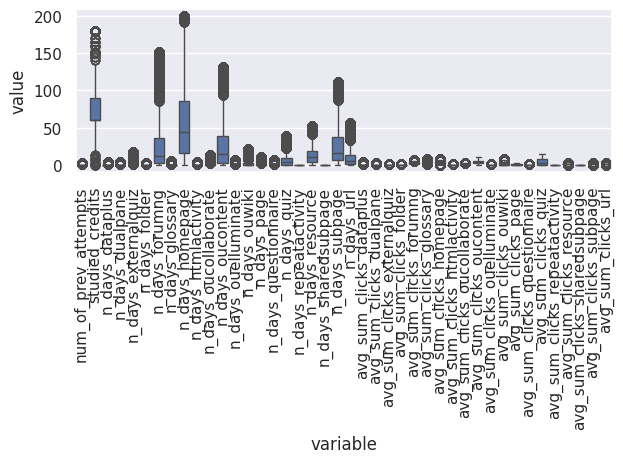

In [ ]:
run_model() # multi algoritmo... para buscar la precision....
# run_cluster_model()
# run_reg_model()

**Modelo Clustering Kmeans**


*   Buscar punto ideal de cantidad de grupos
*   graficar para ver el codo y luego entrenar con la cantidad ideal




In [ ]:
def run_cluster_model():
    df_origen = get_master_vle();
    df_clean, RQ1, df2 = clean_data(df_origen)
    model_scaled =  cluster_alg_model(df_clean)
    display(f"precision del modelo\n{model_scaled}")
    cluster_train_size(model_scaled,df_clean)

def cluster_alg_model(df):

    # Seleccionar las características numéricas para el clustering
    # (las que no son el id_student ni las originales que codificamos)
    X_origen, y = get_x_y(df, 1)
    X = X_origen.copy()

    # Crear el escalador
    scaler = StandardScaler()

    # Escalar los datos
    X_scaled = scaler.fit_transform(X)
    # Método del Codo para encontrar el número óptimo de clústeres
    wcss = []  # WCSS (Within-Cluster Sum of Squares)
    for i in range(1, 11):
        modelkmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
        modelkmeans.fit(X_scaled)
        wcss.append(modelkmeans.inertia_) # inertia_ es el WCSS

    # Graficar el método del codo
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
    plt.title('Método del Codo para encontrar k')
    plt.xlabel('Número de Clústeres (k)')
    plt.ylabel('WCSS')
    plt.grid(True)
    plt.show()

    print("Observa el gráfico para identificar el 'codo' (el punto de inflexión/ la curva se aplana).")
    print("Este punto sugiere un buen valor para k.")
    return X_scaled

def cluster_train_size(X_scaled, df_origen):
    # Elegir el número de clústeres (basado en el método del codo)
    k = 7 # fue donde se acosto la curva o max codo

    # Crear y entrenar el modelo K-Means
    kmeans_model = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans_model.fit_predict(X_scaled)

    # Asignar las etiquetas de clúster al dataframe original
    df_origen['cluster'] = cluster_labels
    # Analizar el tamaño de cada clúster
    print("Tamaño de cada clúster:")
    print(df_origen['cluster'].value_counts())
    print("\n" + "="*50 + "\n")

    # Calcular las medias de las características para cada clúster total_n_days', 'avg_total_sum_clicks
    cluster_summary = df_origen.groupby('cluster')[['avg_total_sum_clicks', 'total_n_days', 'gender', 'disability']].mean()
    print("Resumen de las características por clúster (medias):")
    print(cluster_summary)
    print("\n" + "="*50 + "\n")

    # Analizar la distribución de variables categóricas por clúster
    # Por ejemplo, el resultado final del curso
    print("Distribución del resultado final por clúster:")
    for cluster_id in range(k):
        cluster_data = df_origen[df_origen['cluster'] == cluster_id]
        result_dist = cluster_data[['FResult02_Pass','FResult02_Withdrawn', 'FResult02_Fail']].mean()
        if 'FResult02_Distinction' in cluster_data.columns:
          result_dist = cluster_data[['FResult02_Distinction']].mean()
        print(f"Clúster {cluster_id}:")
        print(result_dist)
        print("-" * 20)

    # Visualizar la distribución de los clústeres en función de las variables de engagement
    sns.pairplot(df_origen, vars=['avg_total_sum_clicks', 'total_n_days'], hue='cluster', palette='viridis')
    plt.suptitle('Distribución de Clústeres basada en Clics y Días de Actividad', y=1.02)
    plt.show()

    # Interpretación de los clústeres
    print("\n--- Interpretación de los Clústeres ---")
    print("Basado en el análisis de las medias, podrías interpretar los clústeres de la siguiente manera:")
    print(f"  - Clúster 0: Podría ser el clúster de estudiantes con {round(cluster_summary.loc[0, 'avg_total_sum_clicks'])} clics en promedio y {round(cluster_summary.loc[0, 'total_n_days'])} días de actividad. Examina sus resultados finales y otras variables para entender su comportamiento.")
    print(f"  - Clúster 1: Estudiantes con ...")
    print(f"  - Clúster 2: Estudiantes con ...")
    print(f"  - Clúster 3: Estudiantes con ...")
    print("...")

**Proyección Aleatoria:**

Esta técnica es muy eficiente desde el punto de vista computacional porque la matriz de proyección se genera aleatoriamente, lo que evita los costosos cálculos de autovalores y autovectores que se requieren en otros métodos como el Análisis de Componentes Principales (PCA).

**¿Por qué usar la Proyección Aleatoria?**
Eficiencia computacional: Es mucho más rápida que el PCA para datos de alta dimensión, ya que no necesita calcular la covarianza de los datos.
Reducción de la maldición de la dimensionalidad: Al reducir la cantidad de características, se pueden mitigar problemas como el sobreajuste y la necesidad de grandes cantidades de datos para entrenar un modelo.
Pre-procesamiento: Se puede utilizar como un paso de pre-procesamiento antes de aplicar algoritmos de aprendizaje automático, mejorando su rendimiento y reduciendo el tiempo de entrenamiento.
Preservación de distancias: Aunque no es perfecta, la proyección aleatoria preserva las distancias entre puntos con una distorsión controlada, lo que la hace útil para tareas como el clustering o la búsqueda de vecinos cercanos.

**Tipos de Proyección Aleatoria en scikit-learn**
* scikit-learn ofrece dos implementaciones principales en el módulo sklearn.random_projection:
* GaussianRandomProjection: La matriz de proyección aleatoria se genera a partir de una distribución normal (gaussiana).
* SparseRandomProjection: La matriz de proyección es dispersa, es decir, la mayoría de sus elementos son cero. Esto la hace aún más eficiente para grandes conjuntos de datos dispersos.








Dimensiones de los datos originales: (500, 1000)
Dimensiones de los datos proyectados: (500, 2)


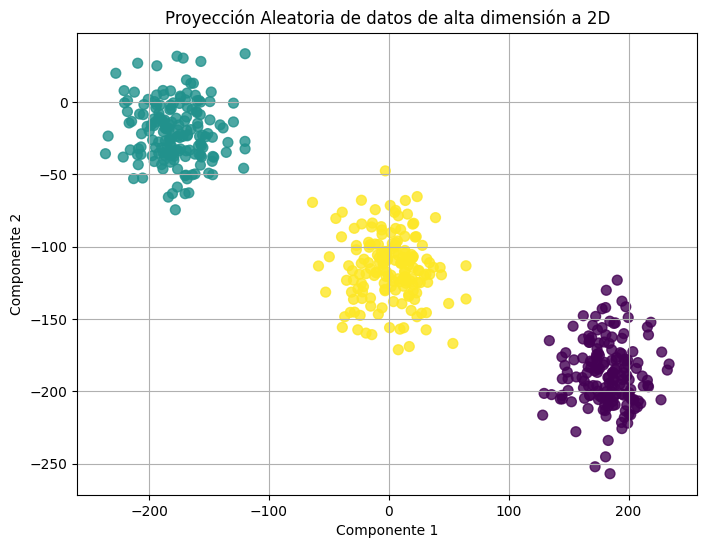

In [ ]:
import numpy as np
from sklearn.random_projection import GaussianRandomProjection
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
# 1. Generar datos de alta dimensión
# Creamos un conjunto de datos con 500 muestras y 1000 características
# para simular un escenario de alta dimensionalidad.
n_samples = 500
n_features = 1000
X, y = make_blobs(n_samples=n_samples, n_features=n_features, centers=3, random_state=42)
print(f"Dimensiones de los datos originales: {X.shape}")
# 2. Definir el número de dimensiones a las que queremos proyectar
# Vamos a reducir las 1000 características a solo 2, para poder visualizarlas
n_components = 2
# 3. Crear una instancia de GaussianRandomProjection
transformer = GaussianRandomProjection(n_components=n_components, random_state=42)
# 4. Ajustar y transformar los datos
# `fit_transform` realiza el ajuste del transformador y la proyección en un solo paso
X_projected = transformer.fit_transform(X)
print(f"Dimensiones de los datos proyectados: {X_projected.shape}")
# 5. Visualizar los datos proyectados
# Podemos ver cómo los clusters originales se mantienen en el espacio de 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_projected[:, 0], X_projected[:, 1], c=y, cmap='viridis', s=50, alpha=0.8)
plt.title('Proyección Aleatoria de datos de alta dimensión a 2D')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.random_projection import SparseRandomProjection
from sklearn.datasets import make_sparse_coded_signal
# 1. Generar datos dispersos de alta dimensión
n_samples = 500
n_features = 5000
n_components = 100
# simula un dataset de alta dimensionalidad, con mucha dispersion
X, dictionary, code = make_sparse_coded_signal(n_samples=n_samples,
                                               n_components=n_features,
                                               n_features=n_features,
                                               random_state=42,n_nonzero_coefs=10)

print(f"Dimensiones de los datos originales (dispersos): {X.shape}")
# 2. Crear una instancia de SparseRandomProjection
transformer_sparse = SparseRandomProjection(n_components=n_components, random_state=42)
# 3. Transformar los datos
X_projected_sparse = transformer_sparse.fit_transform(X)
print(f"Dimensiones de los datos proyectados (dispersos)-filas/columnas: {X_projected_sparse.shape}")

# Opcionalmente, puedes verificar la matriz de proyección
print("\nVerificando la dispersidad de la matriz de proyección:")
projection_matrix = transformer_sparse.components_

# Ahora, la forma correcta de contar los elementos no nulos en una matriz dispersa de SciPy es con el atributo `.nnz`.
# Evitamos usar np.count_nonzero() directamente sobre el objeto de matriz dispersa.
if hasattr(projection_matrix, 'nnz'):
    # Si es una matriz dispersa de SciPy, usa su atributo .nnz
    num_non_zeros = projection_matrix.nnz
    total_elements = projection_matrix.shape[0] * projection_matrix.shape[1]
    density = num_non_zeros / total_elements * 100
    print(f"La matriz de proyección es dispersa (SciPy).")
    print(f"Número de elementos no nulos en la matriz: {num_non_zeros}")
    print(f"Forma de la matriz de proyección: {projection_matrix.shape}")
    print(f"Densidad de la matriz: {density:.2f}%")
else:
    # Si por alguna razón es un array de NumPy, usa np.count_nonzero
    num_non_zeros = np.count_nonzero(projection_matrix)
    total_elements = projection_matrix.size
    density = num_non_zeros / total_elements * 100
    print(f"La matriz de proyección es densa (NumPy).")
    print(f"Número de elementos no nulos en la matriz: {num_non_zeros}")
    print(f"Forma de la matriz de proyección: {projection_matrix.shape}")
    print(f"Densidad de la matriz: {density:.2f}%")

Dimensiones de los datos originales (dispersos): (500, 5000)
Dimensiones de los datos proyectados (dispersos): (500, 100)

Verificando la dispersidad de la matriz de proyección:
La matriz de proyección es dispersa (SciPy).
Número de elementos no nulos en la matriz: 7083
Forma de la matriz de proyección: (100, 5000)
Densidad de la matriz: 1.42%
